<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Basis Functions 2: Ridge and Lasso

##Core Question

In [ ]:
## Feel free to skip this cell to the next one.
%pip install jax[cpu]
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt

## Plotting Helper
def plot_mesh(fig, ax, fn,
    x_data, y_data,
    x_range=(-6, -2),
    y_range=(0, 4),
    N=20,
    cmap="Blues_r",
    show_true=True):

    beta0_s = np.linspace(*x_range, N)
    beta1_s = np.linspace(*y_range, N)
    mesh_b0, mesh_b1 = np.meshgrid(beta0_s, beta1_s)
    params = {"beta_0": mesh_b0.flatten(), "beta_1": mesh_b1.flatten()}

    batched_ll = jax.vmap(fn, in_axes=(0, None, None))
    mesh_y = batched_ll(params, x_data, y_data).reshape(N, N)

    contour = ax.contourf(mesh_b0, mesh_b1, mesh_y, levels=50, cmap=cmap)
    fig.colorbar(contour, ax=ax)
    ax.set_xlabel("Beta0")
    ax.set_ylabel("Beta1")

    min_arg = np.argmin(mesh_y)
    min_x, min_y = mesh_b0.flatten()[min_arg], mesh_b1.flatten()[min_arg]
    ax.scatter(min_x, min_y, marker="x", label="Estimated Minimum")

    if show_true:
        ax.scatter(-5, 3, marker="x", label="True Value")

    ax.set_title("Estimate: beta0={:.2f}, beta1={:.2f}".format(min_x, min_y))
    ax.legend()

## Data helper
def sigmoid(x):
    return np.exp(x) / (1 + np.exp(x))

def generate_data(x):
    a = 3  #beta_1
    b = -5  #beta_0
    prob = sigmoid(a*x+b)
    return np.random.uniform() < prob

def generate_dataset(N):
    x_data = np.random.uniform(high=3, size=N)
    y_data = [generate_data(x) for x in x_data]
    y_data = np.array(y_data, dtype=np.float32)
    return x_data, y_data

In [ ]:
NUM_DATAPOINTS = 1000
x_data, y_data = generate_dataset(NUM_DATAPOINTS)

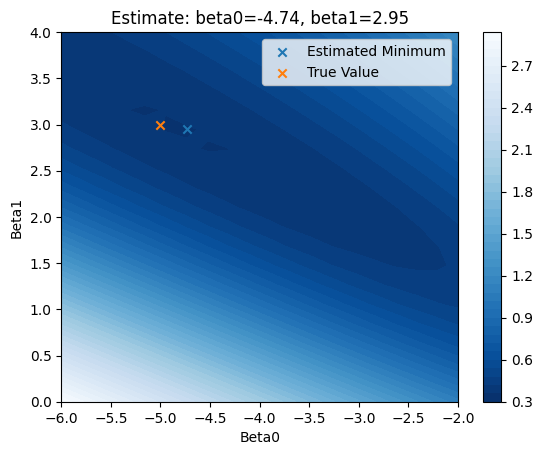

In [ ]:
import jax
import jax.numpy as jnp

@jax.jit
def nll(params, xs, ys):
    logit = params["beta_0"] + params["beta_1"] * xs
    probs = jax.nn.sigmoid(logit)
    likelihood = ys * jnp.log(probs) + (1 - ys) * jnp.log(1 - probs)
    # Note we take the average then negative, NOT the sum.
    return -jnp.mean(likelihood)

fig, ax = plt.subplots()
plot_mesh(fig, ax, nll, x_data, y_data, cmap="Blues_r")
plt.show()

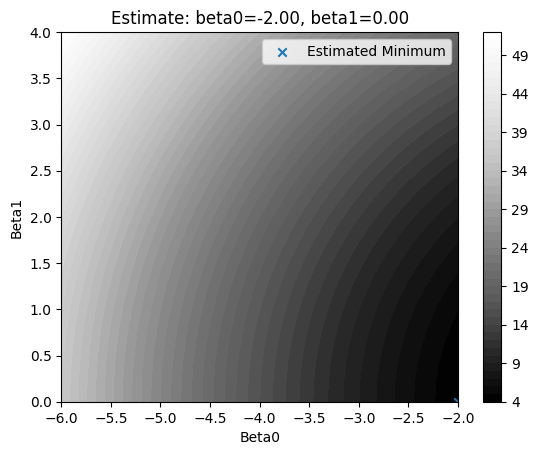

In [ ]:
# Question
@jax.jit
def l2_norm(params, xs, ys):
    beta_0 = params["beta_0"]
    beta_1 = params["beta_1"]
    norm = beta_0**2 + beta_1**2  # Fill this in, keep it simple!
    return norm

fig, ax = plt.subplots()
plot_mesh(fig, ax, l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")
plt.show()

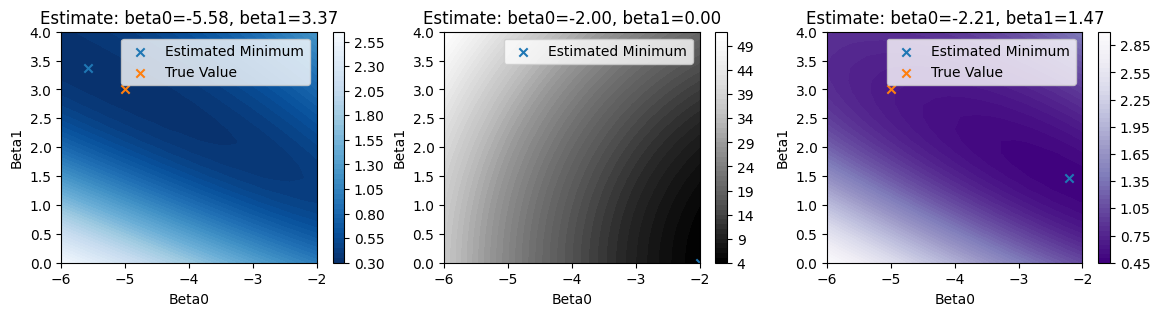

In [ ]:
def modified_loss(params, xs, ys, alpha=1e-2):
    return nll(params, xs, ys) + alpha * l2_norm(params, xs, ys)

# Uncomment the next line when asked
x_data, y_data = generate_dataset(NUM_DATAPOINTS)

fig, ax = plt.subplots(ncols=3, figsize=(14, 3))
plot_mesh(fig, ax[0], nll, x_data, y_data, cmap="Blues_r")
plot_mesh(fig, ax[1], l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")
plot_mesh(fig, ax[2], modified_loss, x_data, y_data, cmap="Purples_r")
plt.show()

##Extension Question

In [ ]:
# Your code here

# I used Claude and ChatGPT to improve my code and also implement some suggestions they made

from sklearn.linear_model import LogisticRegression, RidgeClassifier
import numpy as np
import matplotlib.pyplot as plt

logistic_coefs = []
ridge_coefs = []

for i in range(50):
    x_data, y_data = generate_dataset(NUM_DATAPOINTS)

    # Your code here
    X = x_data.reshape(-1, 1)

    logistic = LogisticRegression(penalty=None)
    ridge = RidgeClassifier(alpha=1e-2)

    logistic.fit(X, y_data)
    ridge.fit(X, y_data)

    # storing intercept: beta_0 and slope: beta_1
    logistic_coefs.append([logistic.intercept_[0], logistic.coef_[0, 0]])
    ridge_coefs.append([ridge.intercept_[0], ridge.coef_[0]])

Logistic Regression variance: [0.13560432 0.04586223]
Ridge Classifier variance: [0.00099798 0.00038763]


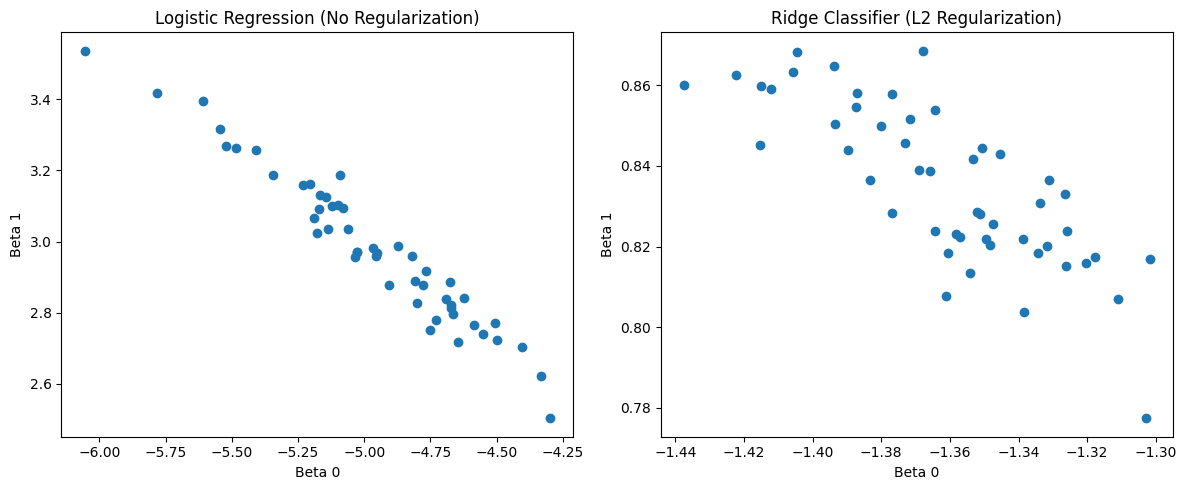

In [ ]:
logistic_coefs = np.array(logistic_coefs)
ridge_coefs = np.array(ridge_coefs)

# variance of each parameter
print("Logistic Regression variance:", np.var(logistic_coefs, axis=0))
print("Ridge Classifier variance:", np.var(ridge_coefs, axis=0))

# coefficient estimates
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(logistic_coefs[:, 0], logistic_coefs[:, 1])
ax[0].set_title("Logistic Regression (No Regularization)")
ax[0].set_xlabel("Beta 0")
ax[0].set_ylabel("Beta 1")
ax[1].scatter(ridge_coefs[:, 0], ridge_coefs[:, 1])
ax[1].set_title("Ridge Classifier (L2 Regularization)")
ax[1].set_xlabel("Beta 0")
ax[1].set_ylabel("Beta 1")
plt.tight_layout()
plt.show()

#Ridge and Lasso on Yosemite

In [1]:
# Yosemite Temp Prediction
# Models:
# 1. Linear Regression (time-of-day baseline)
# 2. RBF Regression (unregularized)
# 3. Ridge Regression (RBF + L2)
# 4. Lasso Regression (RBF + L1)
#
# Train: 2011–2015 (all observations)
# Test: 2016 (entire year)
# Validation: 2015 for alpha selection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

#load dataset

DATA_DIR = Path("/content/Yosemite Data")


# for google drive link
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = Path("/content/drive/MyDrive/Data")

years = range(2011, 2017)
station = "CA_Yosemite_Village_12_W"

all_data = []

for yr in years:

    filename = f"CRNS0101-05-{yr}-{station}.txt"
    matches = list(DATA_DIR.rglob(filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one file for {yr}, "
            f"found {len(matches)}: {filename}"
        )

    file = matches[0]

    # code from Session 12
    # 1 = UTC_DATE
    # 2 = UTC_TIME
    # 8 = AIR_TEMPERATURE

    arr = np.loadtxt(
        file,
        usecols=[1, 2, 8],
        ndmin=2
    )

    all_data.append(arr)

    print(f"Loaded {yr}: {len(arr):,} observations")

data = np.vstack(all_data)

# Missing temperatures are recorded as -9999.
valid = np.isfinite(data[:, 2]) & (data[:, 2] > -1000)

data = data[valid]

# converting UTC time HHMM to minutes after midnight.
data[:, 1] = (
    np.floor_divide(data[:, 1], 100) * 60
    + np.mod(data[:, 1], 100)
)

print("\nTotal valid observations:", f"{len(data):,}")


# variable definitions

dates = data[:, 0].astype(int)
times = data[:, 1]
temps = data[:, 2]

year = dates // 10000

doy = pd.to_datetime(
    dates.astype(str),
    format="%Y%m%d"
).dayofyear.to_numpy(dtype=float)

# sorting by date and time
order = np.lexsort((times, dates))

dates = dates[order]
times = times[order]
temps = temps[order]
year = year[order]
doy = doy[order]

print("\nValid observations per year:")
print(pd.Series(year).value_counts().sort_index())


# data splitting
# 2011–2014: initial training
# 2015: validation
# 2016: final unseen test year

fit_mask = year < 2015
val_mask = year == 2015
train_mask = year < 2016
test_mask = year == 2016

for name, mask in [
    ("Initial training", fit_mask),
    ("Validation", val_mask),
    ("Full training", train_mask),
    ("Testing", test_mask)
]:
    if mask.sum() == 0:
        raise ValueError(f"No observations in {name}")

print("\nDataset split:")
print("Initial training:", f"{fit_mask.sum():,}")
print("Validation:", f"{val_mask.sum():,}")
print("Full training:", f"{train_mask.sum():,}")
print("Testing:", f"{test_mask.sum():,}")


# periodic RBFs from Session 12 code
# Time of day and day of year are periodic
# Circular mapping avoids discontinuities at
# midnight and the beginning of each year

def circ(x, period):

    angle = (
        2 * np.pi
        * np.asarray(x).reshape(-1, 1)
        / period
    )

    return np.hstack([
        np.cos(angle),
        np.sin(angle)
    ])

def gamma_from(sigma, period):
    return 1.0 / (
        2.0 * (2 * np.pi * sigma / period)**2
    )

# RBF centers
daily_centers = np.linspace(
    0, 1440, 24, endpoint=False
)

yearly_centers = np.linspace(
    0, 365.25, 12, endpoint=False
)

# Kernel widths from Session 12
sigma_day = 60.0
sigma_year = 30.0

gamma_day = gamma_from(sigma_day, 1440.0)
gamma_year = gamma_from(sigma_year, 365.25)


def features(t, d):

    # Daily RBF features
    phi_day = rbf_kernel(
        circ(t, 1440.0),
        circ(daily_centers, 1440.0),
        gamma=gamma_day
    )
    # Seasonal RBF features
    phi_year = rbf_kernel(
        circ(d, 365.25),
        circ(yearly_centers, 365.25),
        gamma=gamma_year
    )
    # Interactions between daily and seasonal cycles
    interaction = (
        phi_day[:, ::2, None]
        * phi_year[:, None, ::2]
    ).reshape(len(t), -1)

    return np.hstack([
        phi_day,
        phi_year,
        interaction
    ]).astype(np.float32)


# feature generation for all years
# X_linear: original time-of-day feature
# X_rbf: daily + seasonal + interaction features

X_linear = times.reshape(-1, 1)
X_rbf = features(times, doy)

print("\nRBF feature matrix:", X_rbf.shape)
print("Number of features:", X_rbf.shape[1])


# Linear Regression
# Refit only on years before 2016
linear_model = LinearRegression()
linear_model.fit(
    X_linear[train_mask],
    temps[train_mask]
)
linear_pred = linear_model.predict(
    X_linear[test_mask]
)

# RBF regression (unregularised)
# Linear regression using nonlinear RBF features

rbf_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)
rbf_model.fit(
    X_rbf[train_mask],
    temps[train_mask]
)
rbf_pred = rbf_model.predict(
    X_rbf[test_mask]
)

# Ridge (L2) regression
alphas = np.logspace(-3, 3, 13)
ridge_results = []
best_ridge_alpha = None
best_ridge_rmse = np.inf

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    # Train on 2011–2014
    model.fit(
        X_rbf[fit_mask],
        temps[fit_mask]
    )
    # Validate on 2015
    pred = model.predict(X_rbf[val_mask])

    rmse = np.sqrt(
        mean_squared_error(temps[val_mask], pred)
    )
    ridge_results.append(rmse)

    if rmse < best_ridge_rmse:
        best_ridge_rmse = rmse
        best_ridge_alpha = alpha

print("\nBest Ridge alpha:", best_ridge_alpha)

# refit using all training years (2011–2015)
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_ridge_alpha)
)
ridge_model.fit(
    X_rbf[train_mask],
    temps[train_mask]
)
ridge_pred = ridge_model.predict(
    X_rbf[test_mask]
)

# Lasso (L1) regression
lasso_results = []
best_lasso_alpha = None
best_lasso_rmse = np.inf

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Lasso(
            alpha=alpha,
            max_iter=10000,
            tol=1e-3,
            selection="cyclic"
        )
    )
    model.fit(
        X_rbf[fit_mask],
        temps[fit_mask]
    )
    pred = model.predict(X_rbf[val_mask])
    rmse = np.sqrt(
        mean_squared_error(temps[val_mask], pred)
    )
    lasso_results.append(rmse)
    if rmse < best_lasso_rmse:
        best_lasso_rmse = rmse
        best_lasso_alpha = alpha

print("Best Lasso alpha:", best_lasso_alpha)

# refit on all 2011–2015 observations
lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(
        alpha=best_lasso_alpha,
        max_iter=10000,
        tol=1e-3
    )
)
lasso_model.fit(
    X_rbf[train_mask],
    temps[train_mask]
)
lasso_pred = lasso_model.predict(
    X_rbf[test_mask]
)

Loaded 2011: 105,120 observations
Loaded 2012: 105,408 observations
Loaded 2013: 105,120 observations
Loaded 2014: 105,120 observations
Loaded 2015: 105,120 observations
Loaded 2016: 105,408 observations

Total valid observations: 630,854

Valid observations per year:
2011    104967
2012    105333
2013    105065
2014    105051
2015    105063
2016    105374
2017         1
Name: count, dtype: int64

Dataset split:
Initial training: 420,416
Validation: 105,063
Full training: 525,479
Testing: 105,374

RBF feature matrix: (630854, 108)
Number of features: 108


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.74615e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.74615e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.74615e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.30958e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.68772e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/pytho


Best Ridge alpha: 1000.0
Best Lasso alpha: 0.0031622776601683794


In [9]:
# comparing all four models on 2016 data
y_test = temps[test_mask]
predictions = {
    "Linear Regression": linear_pred,
    "RBF Regression": rbf_pred,
    "Ridge + RBF": ridge_pred,
    "Lasso + RBF": lasso_pred
}
results = []
for name, pred in predictions.items():

    results.append({
        "Model": name,
        "RMSE (C)": np.sqrt(
            mean_squared_error(y_test, pred)
        ),
        "MAE (C)": mean_absolute_error(
            y_test, pred
        ),
        "R2": r2_score(y_test, pred),
        "Bias (C)": np.mean(pred - y_test)
    })
results_df = pd.DataFrame(results)

print("Model Comparison on 2016 data")
print(results_df.round(4).to_string(index=False))

Model Comparison on 2016 data
            Model  RMSE (C)  MAE (C)     R2  Bias (C)
Linear Regression    7.7176   6.4685 0.0178   -0.0818
   RBF Regression    4.6804   3.8565 0.6388   -0.0893
      Ridge + RBF    4.6813   3.8658 0.6386   -0.0893
      Lasso + RBF    4.6805   3.8636 0.6388   -0.0895


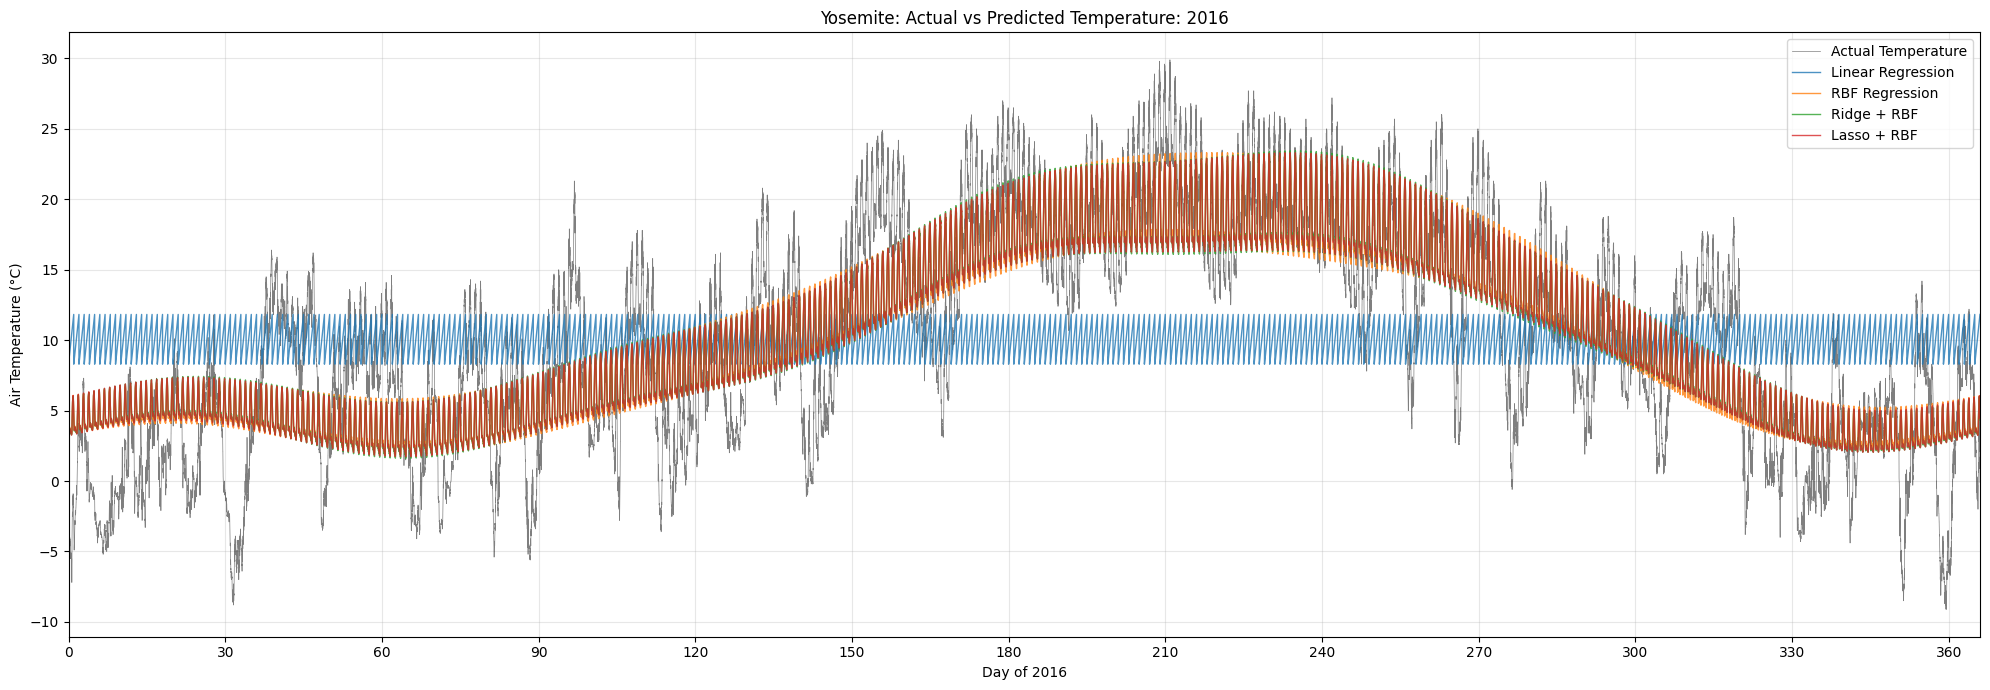

In [10]:
# 11. ACTUAL VS PREDICTED — ENTIRE TEST YEAR (2016)
test_dates = pd.to_datetime(
    dates[test_mask].astype(str),
    format="%Y%m%d"
)

# convert timestamps into fractional days
start_date = pd.Timestamp("2016-01-01")

days_since = (
    (test_dates - start_date).days.to_numpy()
    + times[test_mask] / 1440.0
)

plt.figure(figsize=(20, 7))

# actual temperature
plt.plot(
    days_since,
    y_test,
    color="black",
    linewidth=0.5,
    alpha=0.5,
    label="Actual Temperature"
)

# Predictions from all four models
for name, pred in predictions.items():
    plt.plot(
        days_since,
        pred,
        linewidth=1,
        alpha=0.8,
        label=name
    )

plt.xlabel("Day of 2016")
plt.ylabel("Air Temperature (°C)")
plt.title("Yosemite: Actual vs Predicted Temperature: 2016")

plt.xlim(0, 366)
plt.xticks(np.arange(0, 367, 30))

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

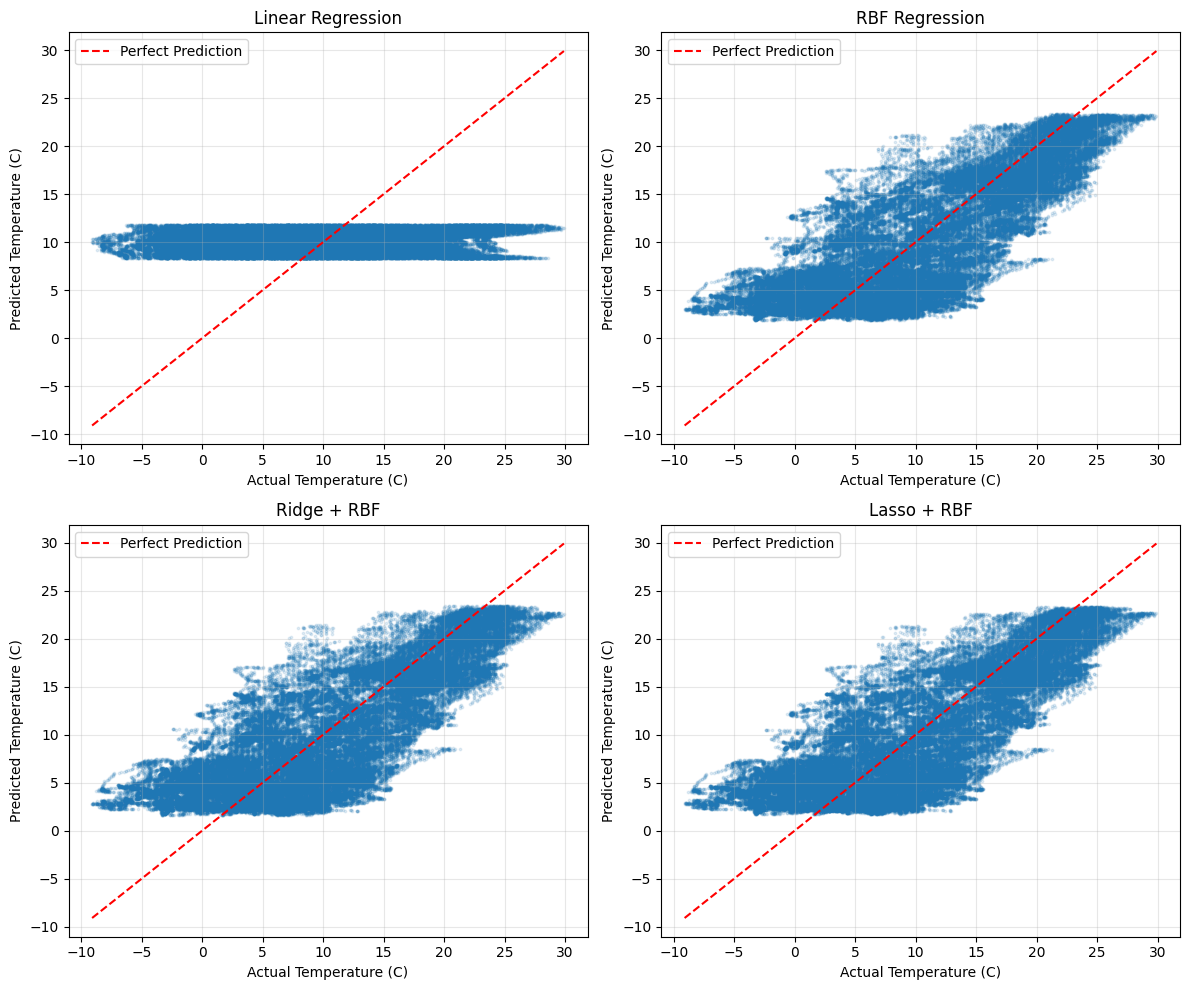

In [4]:
# scatter plots: actual vs predicted
fig, axes = plt.subplots(
    2, 2, figsize=(12, 10)
)

for ax, (name, pred) in zip(
    axes.flatten(),
    predictions.items()
):

    ax.scatter(
        y_test,
        pred,
        s=3,
        alpha=0.12
    )

    limits = [
        min(y_test.min(), pred.min()),
        max(y_test.max(), pred.max())
    ]

    ax.plot(
        limits,
        limits,
        "r--",
        label="Perfect Prediction"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Temperature (C)")
    ax.set_ylabel("Predicted Temperature (C)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

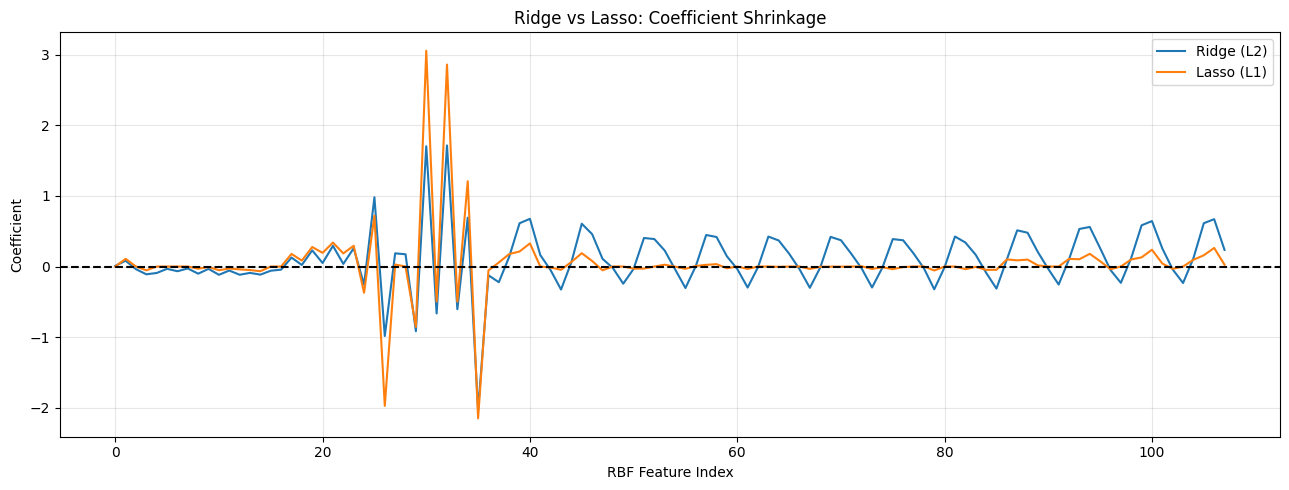


Coefficient Analysis
Total features: 108
Ridge nonzero coefficients: 108
Lasso nonzero coefficients: 82
Lasso zero coefficients: 26


In [5]:
# ridge vs lasso coefficients
ridge_coef = ridge_model.named_steps["ridge"].coef_
lasso_coef = lasso_model.named_steps["lasso"].coef_

plt.figure(figsize=(13, 5))

plt.plot(
    ridge_coef,
    label="Ridge (L2)",
    linewidth=1.5
)

plt.plot(
    lasso_coef,
    label="Lasso (L1)",
    linewidth=1.5
)

plt.axhline(
    0, color="black", linestyle="--"
)

plt.xlabel("RBF Feature Index")
plt.ylabel("Coefficient")
plt.title("Ridge vs Lasso: Coefficient Shrinkage")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nCoefficient Analysis")
print("Total features:", len(ridge_coef))
print(
    "Ridge nonzero coefficients:",
    np.count_nonzero(ridge_coef)
)
print(
    "Lasso nonzero coefficients:",
    np.count_nonzero(lasso_coef)
)
print(
    "Lasso zero coefficients:",
    np.sum(lasso_coef == 0)
)

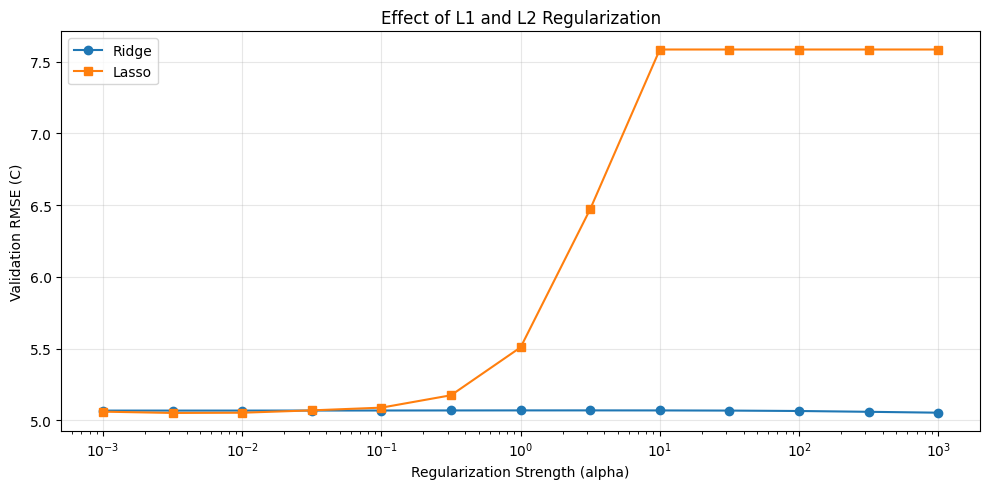

In [6]:
# regularisation strength and error
plt.figure(figsize=(10, 5))

plt.plot(
    alphas,
    ridge_results,
    marker="o",
    label="Ridge"
)

plt.plot(
    alphas,
    lasso_results,
    marker="s",
    label="Lasso"
)

plt.xscale("log")

plt.xlabel("Regularization Strength (alpha)")
plt.ylabel("Validation RMSE (C)")
plt.title("Effect of L1 and L2 Regularization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
#final summary of results
print("Results")
print(results_df.round(4).to_string(index=False))
print("\nBest Ridge alpha:", best_ridge_alpha)
print("Best Lasso alpha:", best_lasso_alpha)
best_model = results_df.loc[
    results_df["RMSE (C)"].idxmin(), "Model"
]
print("\nBest model by test RMSE:", best_model)
print("Test year: 2016")
print("Training years: 2011–2015")

Results
            Model  RMSE (C)  MAE (C)     R2  Bias (C)
Linear Regression    7.7176   6.4685 0.0178   -0.0818
   RBF Regression    4.6804   3.8565 0.6388   -0.0893
      Ridge + RBF    4.6813   3.8658 0.6386   -0.0893
      Lasso + RBF    4.6805   3.8636 0.6388   -0.0895

Best Ridge alpha: 1000.0
Best Lasso alpha: 0.0031622776601683794

Best model by test RMSE: RBF Regression
Test year: 2016
Training years: 2011–2015


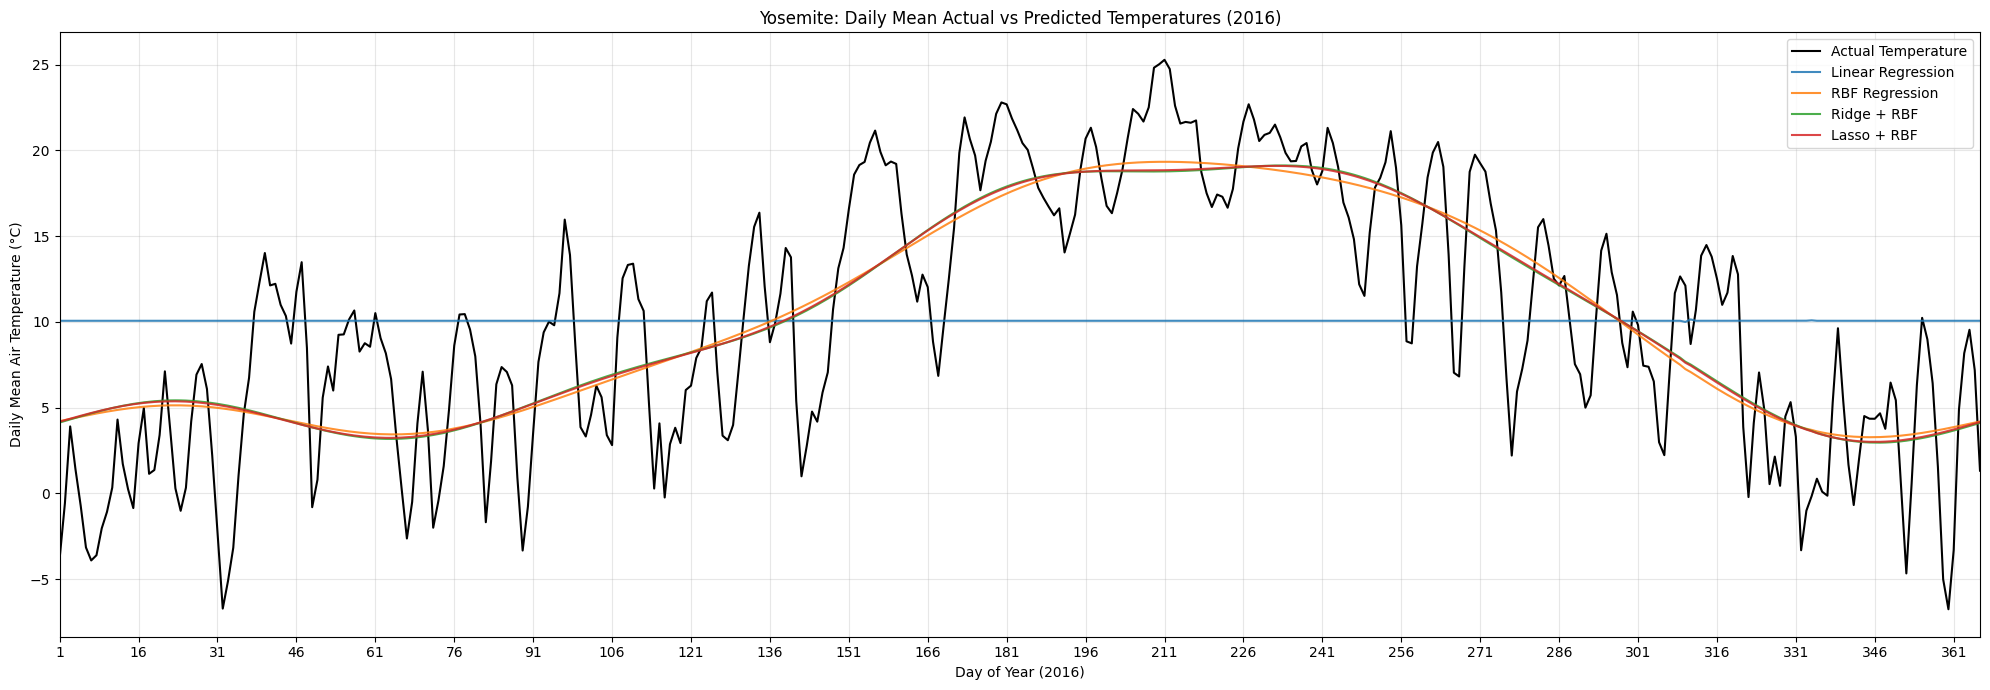

Number of days plotted: 366


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DAILY MEAN TEMPERATURES: ALL 366 DAYS OF 2016

daily_df = pd.DataFrame({
    "date": test_dates,
    "Actual": y_test,
    **predictions
})

# calculate daily mean temperatures
daily_mean = daily_df.groupby("date").mean().sort_index()

# convert dates to day of year (1–366)
day_numbers = daily_mean.index.dayofyear

plt.figure(figsize=(20, 7))

# actual temperature
plt.plot(
    day_numbers,
    daily_mean["Actual"],
    color="black",
    linewidth=1.5,
    label="Actual Temperature"
)

# predictions
for name in predictions:
    plt.plot(
        day_numbers,
        daily_mean[name],
        linewidth=1.5,
        alpha=0.85,
        label=name
    )

# show all 366 days across the x-axis
plt.xlim(1, 366)

# major labels every 15 days
plt.xticks(np.arange(1, 367, 15))

plt.xlabel("Day of Year (2016)")
plt.ylabel("Daily Mean Air Temperature (°C)")
plt.title("Yosemite: Daily Mean Actual vs Predicted Temperatures (2016)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of days plotted:", len(daily_mean))